# N-Asset Effecient Frontier

In [9]:
# Purpose: Load the toolkit and calculate the annualised returns and covariance matrix used by the optimiser.
%load_ext autoreload
%autoreload 2
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import risk_kit as erk

ind = erk.get_ind_returns()
er = erk.annulize_rets(ind["1996":"2000"],12)
cov = ind["1996":"2000"].cov()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [17]:
# Purpose: Import SciPy's constrained optimiser to solve for minimum-volatility portfolio weights.
from scipy.optimize import minimize 

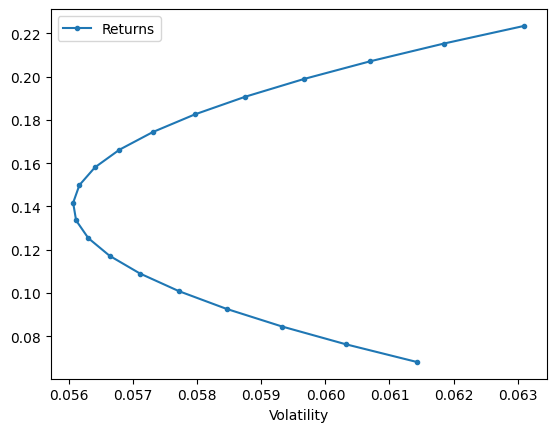

In [18]:
# Purpose: Start with a two-asset frontier as a visual reference before generalising to more assets.
l=["Games","Fin"]
erk.plot_ef2(20,er[l],cov.loc[l,l])

In [19]:
# Purpose: Minimise volatility while enforcing a chosen target return, fully invested weights, and long-only positions.
def minimize_vol(target_return,er,cov):
    """
    target return --> weight
    """
    n=er.shape[0]
    init_guess=np.repeat(1/n,n)
    bounds=((0.0,1.0),)*n
    # Checking whether return is target or not 
    return_is_target={
        'type':'eq',
        'args':(er,),
        'fun': lambda weights,er: target_return - erk.portfolio_return(weights,er) 
    }#To check if target is met (=0)
    weights_sum_to_1 = {
        'type':'eq',
        'fun': lambda weights: np.sum(weights)-1
    }
    results = minimize(
        erk.portfolio_vol,
        init_guess,
        args=(cov,),
        method="SLSQP",#Quadratic programming optimizer
        constraints=(return_is_target,weights_sum_to_1),
        bounds=bounds
    )
    return results.x

In [20]:
# Purpose: Check the optimiser on a 15% target-return portfolio before applying it across the frontier.
# Testing function for 2-asset case (target is 15% return)
w15 = minimize_vol(0.15,er[l],cov.loc[l,l])
v15 = erk.portfolio_vol(w15,cov.loc[l,l])
v15

np.float64(0.05616366940670658)

In [22]:
# Purpose: Solve the constrained problem for many target returns and plot the resulting N-asset frontier.
def optimal_weights(n_points, er, cov):
    """
    List of weights to run the optimizer on to minimize vol
    """
    target_rets = np.linspace(er.min(),er.max())
    weights = [minimize_vol(target_return,er,cov) for target_return in target_rets]
    return weights
def plot_ef(n_points,er,cov,style=".-"):
    """
    Plots the N-asset efficient frontier 
    """
    weights= optimal_weights(n_points,er,cov)
    rets = [erk.portfolio_return(w,er) for w in weights]
    vols = [erk.portfolio_vol(w,cov) for w in weights]
    ef = pd.DataFrame({
        "Returns":rets,
        "Volatility":vols
    })
    ef.plot.line(x="Volatility",y="Returns",style=".-")

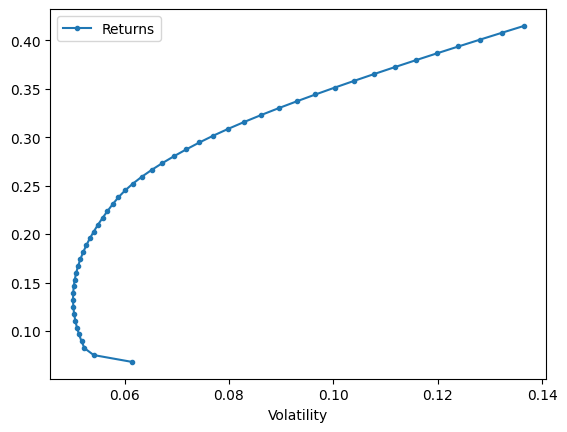

In [24]:
# Purpose: Apply the N-asset frontier function to four industries with their matching covariance submatrix.
l2 = ['Smoke','Fin','Games','Coal']
plot_ef(25,er[l2],cov.loc[l2,l2])